# 02 · Modeling and Analysis

Linear regression on what drives EV adoption, k-means segmentation of ZIP codes, and a ranking of where new public chargers are needed most.

**Authors:** Andrew Salah & Bradley Shea · MSBA 502, University of San Diego

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf   # regression

## Load clean data

In [2]:
# Load the clean data (saved from the cleaning notebook)
df = pd.read_csv("../data/processed/ev_clean_by_zip.csv", dtype={"zip": str})

# Remove outlier: 94304 (Palo Alto) is 57% EVs - likely corporate fleet registrations
df = df[df["zip"] != "94304"]

# Rescale variables so coefficients are easy to explain
df["ev_share_pct"] = df["ev_share"] * 100          # EV share in %
df["income_10k"]   = df["median_income"] / 10000   # income in $10K units
df["home_own_pct"] = df["home_ownership"] * 100    # home ownership in %
df["pop_10k"]      = df["population"] / 10000      # population in 10K units
print(df.shape)

(1387, 26)


## Linear regression: what drives EV adoption?

In [3]:
# What drives EV adoption? EV share explained by income, home ownership, population
model = smf.ols("ev_share_pct ~ income_10k + home_own_pct + pop_10k", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           ev_share_pct   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.730
Method:                 Least Squares   F-statistic:                     1250.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:09:15   Log-Likelihood:                -3447.3
No. Observations:                1387   AIC:                             6903.
Df Residuals:                    1383   BIC:                             6924.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.8305      0.317      2.621   

## Model fit and residuals

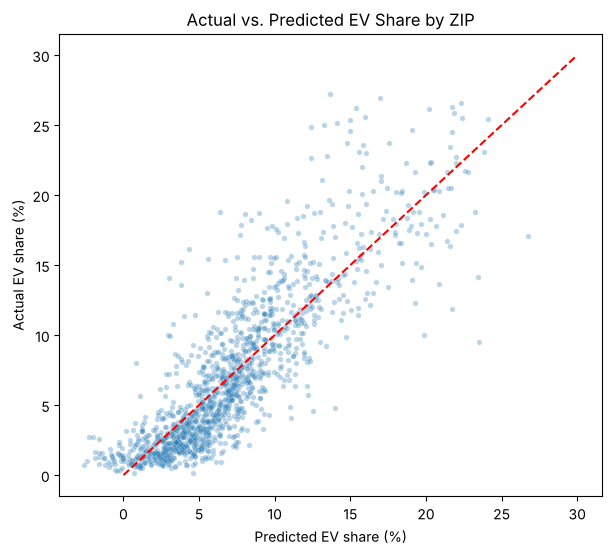

In [4]:
# Save predictions and residuals for each ZIP
df["predicted_ev_pct"] = model.fittedvalues
df["residual"] = model.resid   # negative = fewer EVs than the model expects

# Plot actual vs. predicted
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x="predicted_ev_pct", y="ev_share_pct", alpha=0.3, s=15, ax=ax)
ax.plot([0, 30], [0, 30], color="red", linestyle="--")   # perfect-prediction line
ax.set(title="Actual vs. Predicted EV Share by ZIP",
       xlabel="Predicted EV share (%)", ylabel="Actual EV share (%)")
plt.show()

## K-means clustering: choose k

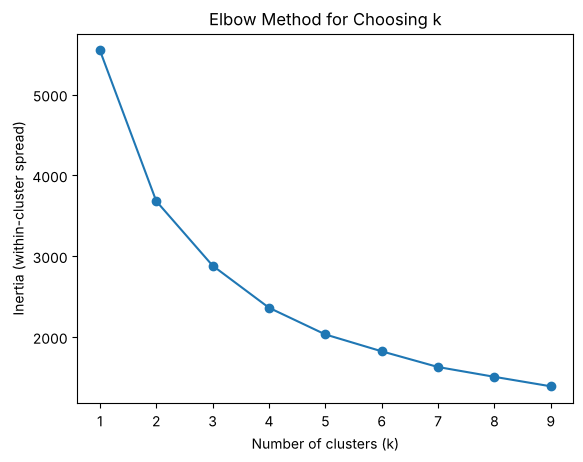

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Charger coverage: public ports per 100 EVs (works even for ZIPs with 0 ports)
df["ports_per_100_evs"] = df["total_ports"] / df["ev"] * 100

# Features to group ZIPs on: demand, charger supply, growth potential, income
features = ["ev_share_pct", "ports_per_100_evs", "residual", "income_10k"]
X = df[features].copy()
X["ports_per_100_evs"] = np.log1p(X["ports_per_100_evs"])   # tame extreme values
X_scaled = StandardScaler().fit_transform(X)                 # put all on same scale

# Elbow method: where does adding clusters stop helping much?
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_
           for k in range(1, 10)]
plt.plot(range(1, 10), inertia, marker="o")
plt.title("Elbow Method for Choosing k")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia (within-cluster spread)")
plt.show()

## K-means clustering: segments

In [6]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X_scaled)

# Profile each cluster
profile = df.groupby("cluster").agg(
    zips=("zip", "count"),
    avg_ev_share=("ev_share_pct", "mean"),
    ports_per_100_evs=("ports_per_100_evs", "median"),
    avg_residual=("residual", "mean"),
    avg_income=("median_income", "mean"),
    zero_charger_zips=("total_ports", lambda s: (s == 0).sum()))

# Name clusters by their profile (so names stay correct even if numbers shuffle)
names = {}
remaining = profile.copy()
names[remaining["ports_per_100_evs"].idxmax()] = "Well-Served"
remaining = remaining.drop(remaining["ports_per_100_evs"].idxmax())
names[remaining["avg_residual"].idxmax()] = "Hot Markets"
remaining = remaining.drop(remaining["avg_residual"].idxmax())
names[remaining["avg_income"].idxmax()] = "Affluent Adopters"
remaining = remaining.drop(remaining["avg_income"].idxmax())
names[remaining.index[0]] = "Emerging & Underserved"

df["segment"] = df["cluster"].map(names)
profile["segment"] = profile.index.map(names)
profile.round(2)

,zips,avg_ev_share,ports_per_100_evs,avg_residual,avg_income,zero_charger_zips,segment
cluster,,,,,,,
0,380,3.85,8.44,-0.83,77148.09,0,Well-Served
1,195,14.21,1.42,-1.09,177866.47,20,Affluent Adopters
2,187,14.74,1.60,5.05,123121.91,7,Hot Markets
3,625,4.58,0.72,-0.66,90453.42,226,Emerging & Underserved


## Ranking: ports needed per ZIP

In [7]:
# Statewide benchmark: EVs per public port across California
state_ratio = df["ev"].sum() / df["total_ports"].sum()
print(f"California average: {state_ratio:.1f} EVs per public port")

# EVs beyond what local chargers support at the state average
df["unserved_evs"] = df["ev"] - df["total_ports"] * state_ratio
df["ports_needed"] = (df["unserved_evs"] / state_ratio).clip(lower=0).round()

top20 = df.nlargest(20, "unserved_evs")[
    ["zip", "segment", "ev", "total_ports", "evs_per_port", "ports_needed", "median_income"]]
top20 #This is the top 20 potential new EV stations

California average: 32.5 EVs per public port


,zip,segment,ev,total_ports,evs_per_port,ports_needed,median_income
511,92620,Hot Markets,9716,31.0,313.419355,268.0,146942.0
927,94582,Hot Markets,8254,18.0,458.555556,236.0,214677.0
897,94539,Affluent Adopters,9847,74.0,133.067568,229.0,243552.0
1269,95747,Hot Markets,7800,28.0,278.571429,212.0,136750.0
536,92677,Hot Markets,7355,28.0,262.678571,198.0,140452.0
895,94536,Affluent Adopters,7055,19.0,371.315789,198.0,167662.0
896,94538,Hot Markets,13172,211.0,62.426540,194.0,147301.0
1033,95120,Affluent Adopters,6427,5.0,1285.400000,193.0,250000.0
372,92130,Affluent Adopters,10291,129.0,79.775194,187.0,205680.0
244,91709,Hot Markets,8930,96.0,93.020833,178.0,126350.0


## San Diego close-up

In [8]:
sd = df[df["zip"].str[:3].isin(["919", "920", "921"])]
sd.nlargest(10, "unserved_evs")[["zip", "segment", "ev", "total_ports", "ports_needed"]]
#This is San Diego Specific

,zip,segment,ev,total_ports,ports_needed
372,92130,Affluent Adopters,10291,129.0,187.0
293,91913,Emerging & Underserved,4654,7.0,136.0
373,92131,Affluent Adopters,4813,28.0,120.0
311,92009,Affluent Adopters,5348,58.0,106.0
333,92064,Affluent Adopters,4712,43.0,102.0
368,92126,Emerging & Underserved,5374,71.0,94.0
318,92024,Affluent Adopters,5477,76.0,92.0
369,92127,Hot Markets,7509,139.0,92.0
370,92128,Hot Markets,4804,60.0,88.0
371,92129,Affluent Adopters,5919,95.0,87.0


## Top 20 chart

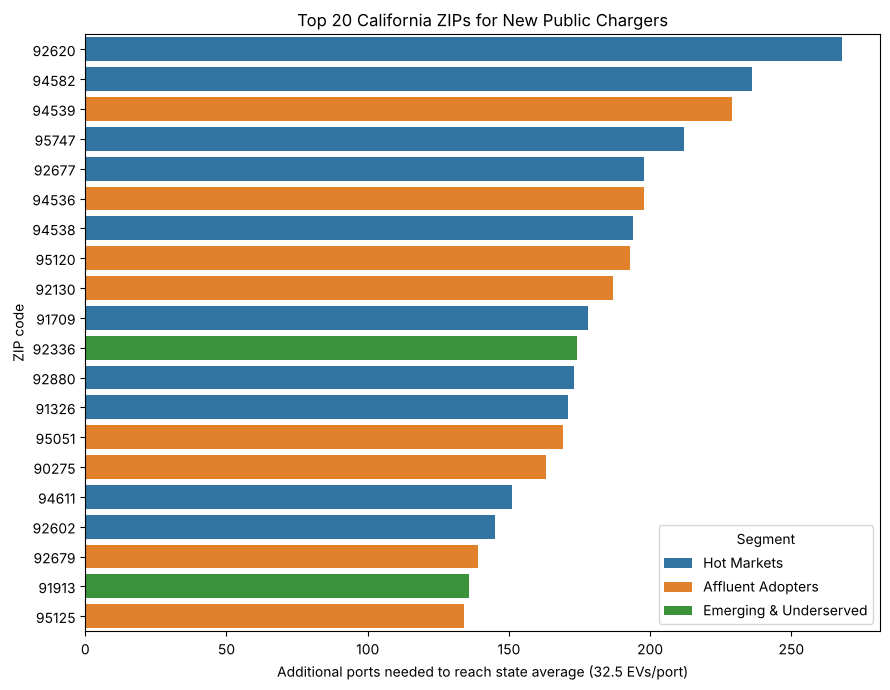

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=top20, y="zip", x="ports_needed", hue="segment", dodge=False, ax=ax)
ax.set(title="Top 20 California ZIPs for New Public Chargers",
       xlabel="Additional ports needed to reach state average (32.5 EVs/port)",
       ylabel="ZIP code")
ax.legend(title="Segment")
plt.tight_layout()
plt.show()

## Save results

In [10]:
# Save full results (every ZIP with its segment and gap) and the top-20 list
df.to_csv("../data/processed/ev_results_by_zip.csv", index=False)
top20.to_csv("../data/processed/top20_charger_targets.csv", index=False)